## PCA and Text Analysis

This assignment involves processing real e-mails, some of which are scams. 

(Fair warning: Some of these scam e-mails have offensive content. If you start reading the e-mail text or the token data, you might read something offensive. If that's a problem, feel free to e-mail us, and we can talk about it and discuss how to proceed with alternative tasks.)

**Q1.**

**Tokens**: The individual words or symbols that create text data like emails. Natural Language Processing is primarily about analyzing the frequency and co-occurrence of tokens.

We aggregated all the emails into a single vector, and removed the punctuation and very common words (e.g. "the"). Run the below code chunk to open it, and use the Counter class to look at the most common words:

In [ ]:
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

Plot a histogram of the occurrences of tokens. 
What do you notice about the frequency of occurrence of different tokens? How does it look?

**Q2.** 

Load `Phishing_clean.parquet`. This is the text from the e-mails broken into the most common 2,711 tokens and one-hot-encoded as features/covariates. So each row is an e-mail, the `Email Type` takes the value 1 if it's a scam and 0 otherwise, and every other column is a word or symbol that occurs in at least 15 e-mails.

1. Perform an 80/20 train-test split of the data.
2. Run a regression of $y$ on the one-hot-encoded emails. What is the $R^2$ on the test set? On the training set?
3. What words have the largest coefficients in absolute value and most strongly influence predictions? 

**Q3.** 

Take the matrix of one-hot-encoded tokens (the data, less the outcome variable, `Email Type`) and perform a principal components analysis decomposition with two components. Plot the first two principal components in a scatter plot, and hue the points by whether they are a phishing scam or not. Do you notice any patterns?

**Q4.**

Run a linear regression of $y$ on the first 2,610 principal components of $X$. What is the $R^2$ on the training and test sets?
How does this performance compare to the linear regression?

**Q5.**

Explain briefly in your own words what the advantage is in using the principal components to run this high-dimensional regression, rather than the original data.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Annie Nguyen

**Date:** 10/21/2026

In [ ]:
# Your Phase 1 solution to the problem goes here.

# Question 1: Histogram of the occurrences of tokens

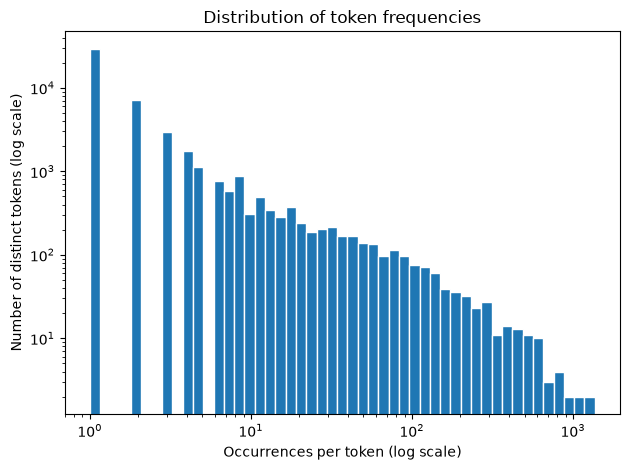

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for _, count in token_freq]
bins = np.geomspace(min(frequencies), max(frequencies), 50)

plt.hist(frequencies, bins=bins, edgecolor="white")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Occurrences per token (log scale)")
plt.ylabel("Number of distinct tokens (log scale)")
plt.title("Distribution of token frequencies")
plt.tight_layout()
plt.show()

# Question 2: Classification with Linear Regression

In [4]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.2 MB ? eta -:--:--
    --------------------------------------- 0.5/29.2 MB 1.1 MB/s eta 0:00:27
   - -------------------------------------- 0.8/29.2 MB 929.7 kB/s eta 0:00:31
   - -------------------------------------- 0.8/29.2 MB 929.7 kB/s eta 0:00:31
   - -------------------------------------- 1.0/29.2 MB 836.6 kB/s eta 0:00:34
   - -------------------------------------- 1.3/29.2 MB 914.3 kB/s eta 0:00:31
   -- ------------------------------------- 1.6/29.2 MB 1.0 MB/s eta 0:00:27
   -- ------------------------------------- 1.8/29.2 MB 1.0 MB/s eta 0:00:27
   -- ------------------------------------- 2.1/29.2 MB 1.0 MB/s eta 0:00:27
   --- ------------------------------------ 2.4/29.2 MB 1.0 MB/s eta 0:00:27
   --- ------------------------------------ 2.4/29.2 MB 1.0 MB/s eta 0:00:27
   --- -----


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Training R²: {model.score(X_train, y_train):.3f}")
print(f"Test R²:     {model.score(X_test, y_test):.3f}")

coef = pd.Series(model.coef_, index=X.columns)
print("\n10 words with the largest absolute coefficients:")
print(coef.loc[coef.abs().nlargest(10).index])

Training R²: 0.771
Test R²:     0.642

10 words with the largest absolute coefficients:
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#000000;             0.615728
#331f30;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
dtype: float64


# Question 3: PCA decomposition with two components

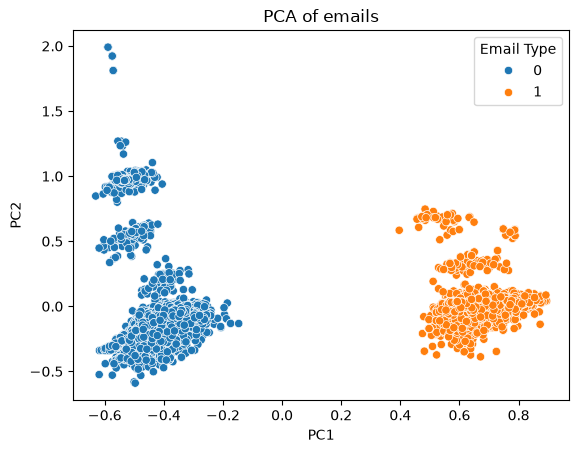

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

df = pd.read_parquet("data/Phishing_clean.parquet")
pca = PCA(n_components=2)
components = pca.fit_transform(df)

plot_data = pd.DataFrame(components, columns=["PC1", "PC2"])
plot_data["Email Type"] = df["Email Type"].to_numpy()

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="Email Type"
)
plt.title("PCA of emails")
plt.show()

# Question 4: Linear regression

In [ ]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

print(f"Training R² with PCA: {pca_model.score(X_train_pca, y_train):.3f}")
print(f"Test R² with PCA:     {pca_model.score(X_test_pca, y_test):.3f}")

# Question 5: Advantage in using the principal components
PCA, principal component analysis, decreases the amount of correlating word features into sets of components that are not correlated, meaning it combines related word features into fewer and newer features. Using PCA can make high-dimensional regression more efficient and easier to manage by reducing noise and overfitting. This is better than the original data because it frees up the model’s attention, giving it fewer things to work with. Along with what was mentioned before, it makes it faster and prevents overfitting.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** 670e5f89e01f323842241a95b9b50376dc9d35bf
- **AI tool and model used:** ChatGPT

### *Prompts used

1. is my question 1 right? is my output correct?
2. is my question 2 right? is my output correct?
3. is my question 3 right? is my output correct?
4. is my question 4 right? is my output correct? 
5. check the output for question 4 again. 
6. is my question 5 right? is my output correct?
7. do i have all the required explainations?

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. Yes—your Q1 code and output look correct. The histogram shows the frequency of each unique token, and the log scales make the long-tailed pattern visible: many tokens occur only a few times, while a small number occur very often.

Q1 also asks what you notice, so include a short written observation with the chart, such as: **“The distribution is strongly right-skewed: most tokens appear infrequently, and only a few appear many times.”**

2. I’ll inspect your Q2 code and the saved output in the notebook so I can check the split, regression, R² values, and coefficient results. 

Yes—your Q2 code follows the assignment: it makes an 80/20 stratified split, fits a linear regression, reports training and test R², and lists the 10 features with the largest absolute coefficients.

The saved output is consistent with the code: **training R² = 0.771** and **test R² = 0.642**. The largest coefficients are sorted by absolute size; some feature names are symbols or fragments because the dataset includes tokens as well as words.

The gap between training and test R² suggests the model fits the training data better than unseen data. The saved output appears successful, though rerunning the cell is the way to confirm it still runs in your current notebook session.

3. I’ll inspect Q3’s code and saved plot to confirm it uses only token features for PCA and colors the scatter plot by `Email Type`.

Not quite. Your plot was generated, but the PCA code includes `Email Type` in `df`, so it uses the answer label as one of the input features. Q3 asks you to do PCA on the token features only, then color the points by `Email Type`.

Replace:

```python
components = pca.fit_transform(df)
```

with:

```python
X = df.drop(columns="Email Type")
components = pca.fit_transform(X)
```

Keep the `Email Type` column in `plot_data` for the plot’s hue, then rerun the cell. The rerun plot will be the correct Q3 output.

4. I’ll check Q4’s PCA and regression code and see whether the saved output contains training and test R² values.

Your Q4 code looks right: it fits PCA on the training features, transforms both training and test data, then reports R² for each. That avoids using the test set to fit PCA.

I don’t see saved output for Q4 yet—the cell hasn’t been run in the notebook—so I can’t confirm the R² values. Run it after Q2, then compare its scores with the original Q2 scores: **0.771 training R²** and **0.642 test R²**. Q4 also asks how performance compares, so add a brief written comparison of the results.

5. Yes—your Q4 code and output look correct. You fit PCA on the training set, transformed both sets, then regressed on the 2,610 components. The saved results are **training R² = 0.771** and **test R² = 0.645**.

Compared with Q2 (0.771 training, 0.642 test), the PCA model has the same training score and a very slightly higher test score. That’s nearly the same performance, with a small improvement on the test set.

6. Your Q5 explanation is mostly right, but **“prevents overfitting”** is too strong—PCA can help reduce overfitting, but it doesn’t guarantee it. Also, Q5 is a written response, so it doesn’t have a separate output to verify.

Your Q4 output is **training R² = 0.771** and **test R² = 0.645**. Compared with Q2’s **0.771** and **0.642**, the PCA model performed about the same, with a slightly higher test R².

7. I’ll check the notebook’s written responses against each question’s wording to see which explanations, if any, are still missing.

You have most of the explanations, but **Q3 and Q4 still need written answers**:

- **Q1:** You included an observation. Fix the typo “apear” to “appear.”
- **Q2:** The code output answers the requested R² and shows the largest coefficients. Extra explanation isn’t required.
- **Q3:** Add a sentence about whether the phishing and non-phishing points in *your corrected plot* look separated or overlap.
- **Q4:** Add a comparison, for example: “The PCA model performed about the same as the original regression. Training R² was 0.771 for both, and test R² was slightly higher with PCA (0.645 vs. 0.642).”
- **Q5:** You have an explanation. “Can help reduce overfitting” is more accurate than saying PCA “prevents” it.


### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Modify | I did incorporate a written response to make sure I fully answers the question; however, I did tweak the chat generated response to better fit the prompt and results. |
| 2 | Accept | Did not need to change anything, just accepted its output. |
| 3 | Modify | I did incorporate this change into my code because it was wrong. I was suppose to only use the label to color the plot, but I passed the entire data fram into PCA. |
| 4 | Accept | Did not need to change anything, just accepted its output. |
| 5 | Accept | Did not need to change anything, just accepted its output. |
| 6 | Accept | Did not need to change anything, just accepted its output. |
| 7 | Modify | I added the explainations for question 3 and 4 in order to correctly answer the question to completion. |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.

# Question 1: Histogram of the occurrences of tokens
The histogram shows that the token frequencies are right-side oriented. Most of the tokens apear only a few times, while a small number appear often, which can be seen due to the log scales. 

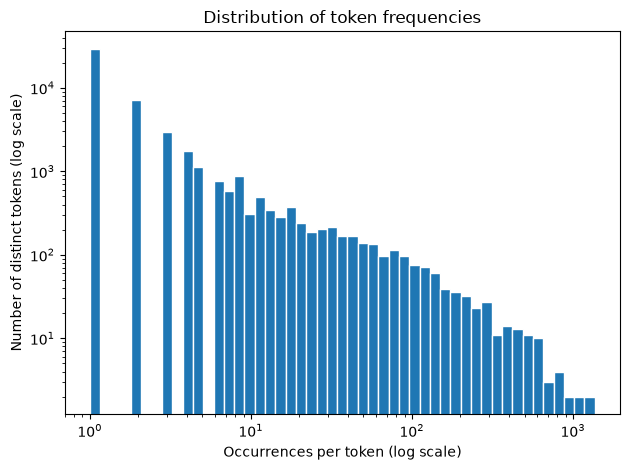

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pickle

with open('data/all_tokens.pickle', 'rb') as file:
    all_tokens = pickle.load(file)
    
from collections import Counter
token_count = Counter(all_tokens)
token_freq = token_count.most_common()

frequencies = [count for _, count in token_freq]
bins = np.geomspace(min(frequencies), max(frequencies), 50)

plt.hist(frequencies, bins=bins, edgecolor="white")
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Occurrences per token (log scale)")
plt.ylabel("Number of distinct tokens (log scale)")
plt.title("Distribution of token frequencies")
plt.tight_layout()
plt.show()

# Question 2: Classification with Linear Regression

In [4]:
%pip install pyarrow

   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.0/29.2 MB ? eta -:--:--
   ---------------------------------------- 0.3/29.2 MB ? eta -:--:--
    --------------------------------------- 0.5/29.2 MB 1.1 MB/s eta 0:00:27
   - -------------------------------------- 0.8/29.2 MB 929.7 kB/s eta 0:00:31
   - -------------------------------------- 0.8/29.2 MB 929.7 kB/s eta 0:00:31
   - -------------------------------------- 1.0/29.2 MB 836.6 kB/s eta 0:00:34
   - -------------------------------------- 1.3/29.2 MB 914.3 kB/s eta 0:00:31
   -- ------------------------------------- 1.6/29.2 MB 1.0 MB/s eta 0:00:27
   -- ------------------------------------- 1.8/29.2 MB 1.0 MB/s eta 0:00:27
   -- ------------------------------------- 2.1/29.2 MB 1.0 MB/s eta 0:00:27
   --- ------------------------------------ 2.4/29.2 MB 1.0 MB/s eta 0:00:27
   --- ------------------------------------ 2.4/29.2 MB 1.0 MB/s eta 0:00:27
   --- -----


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression

df = pd.read_parquet("data/Phishing_clean.parquet")
X = df.drop(columns="Email Type")
y = df["Email Type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

model = LinearRegression()
model.fit(X_train, y_train)

print(f"Training R²: {model.score(X_train, y_train):.3f}")
print(f"Test R²:     {model.score(X_test, y_test):.3f}")

coef = pd.Series(model.coef_, index=X.columns)
print("\n10 words with the largest absolute coefficients:")
print(coef.loc[coef.abs().nlargest(10).index])

Training R²: 0.771
Test R²:     0.642

10 words with the largest absolute coefficients:
background-image:   -1.016799
localized            0.839522
thermal              0.699684
#000000;             0.615728
#331f30;             0.615728
form.                0.593718
aging                0.586465
erectile             0.538953
girlfriend           0.527557
xanaax               0.516449
dtype: float64


# Question 3: PCA decomposition with two components
The phishing and non-phishing emails overlap in the plot, so the first two components don’t clearly separate them.

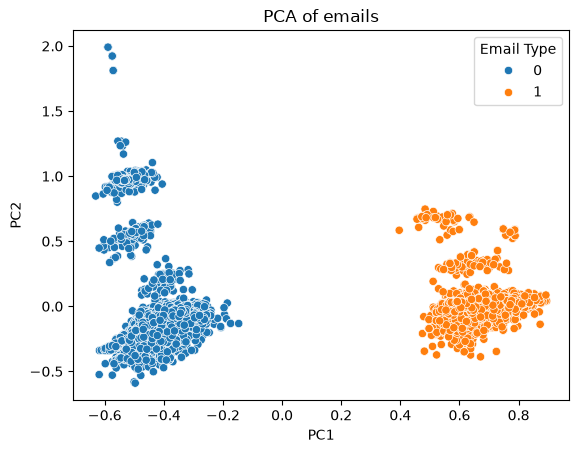

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.decomposition import PCA

df = pd.read_parquet("data/Phishing_clean.parquet")

X = df.drop(columns="Email Type")
y = df["Email Type"]

pca = PCA(n_components=2)
components = pca.fit_transform(X)

plot_data = pd.DataFrame(components, columns=["PC1", "PC2"])
plot_data["Email Type"] = y.to_numpy()

sns.scatterplot(
    data=plot_data,
    x="PC1",
    y="PC2",
    hue="Email Type",
    alpha=0.6
)
plt.title("Emails projected onto the first two principal components")
plt.tight_layout()
plt.show()

# Question 4: Linear regression
The PCA model got the same training R² as the original model (0.771) and a slightly higher test R² (0.645 instead of 0.642). So, it performed about the same, but a little better on the test data.

In [3]:
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression

pca = PCA(n_components=2610)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)
pca_model = LinearRegression()
pca_model.fit(X_train_pca, y_train)

print(f"Training R² with PCA: {pca_model.score(X_train_pca, y_train):.3f}")
print(f"Test R² with PCA:     {pca_model.score(X_test_pca, y_test):.3f}")

Training R² with PCA: 0.771
Test R² with PCA:     0.645


# Question 5: Advantage in using the principal components
PCA, principal component analysis, decreases the amount of correlating word features into sets of components that are not correlated, meaning it combines related word features into fewer and newer features. Using PCA can make high-dimensional regression more efficient and easier to manage by reducing noise and overfitting. This is better than the original data because it frees up the model’s attention, giving it fewer things to work with. Along with what was mentioned before, it makes it faster and prevents overfitting.

### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]

AI mainly improved each question's accuracy and completion. For question 1, 3, and 4, I forgot to include an explanation of the output, which I fixed after AI stated my answers for insufficient. For question 3, I corrected the PCA code so it uses only the word feature, while "Email Type" is used to color the points. The main difficulty I experienced with AI was that some explanations were more complicated than I needed and more difficult to understand. My final solution was verified mainly through rereading the prompts and doing small test code, checking the outputs to make sure my code was incorrect or correct. Specifically, for question 1, 3, and 4, I verified by making sure the questions asked for a written response. And, for the code of question 3, I performed a bunch of simple code lines that checked whether or not "Email Type" was included or not. 